22-7-26
Day=21(23)
Wednesday

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [4]:
df=pd.read_csv("customer_churn_nlp.csv")
print(df.shape)
print(df.head())
df.head()

(500, 7)
  CustomerID  Tenure  MonthlyCharges  SupportTickets        Contract  \
0  CUST-1000      40           35.09               0        One year   
1  CUST-1001      22           50.26               0        One year   
2  CUST-1002      13           64.71               1  Month-to-month   
3  CUST-1003      23           58.64               0        One year   
4  CUST-1004      53           27.57               2        One year   

                                    CustomerFeedback  Churn  
0      Customer support was very helpful and polite.      0  
1         Smooth connection and fair monthly prices.      0  
2  Excellent coverage and fast streaming experience.      0  
3     Great service, very happy with internet speed!      0  
4          Easy billing process and fast resolution.      0  


,CustomerID,Tenure,MonthlyCharges,SupportTickets,Contract,CustomerFeedback,Churn
0,CUST-1000,40,35.09,0,One year,Customer support was very helpful and polite.,0
1,CUST-1001,22,50.26,0,One year,Smooth connection and fair monthly prices.,0
2,CUST-1002,13,64.71,1,Month-to-month,Excellent coverage and fast streaming experience.,0
3,CUST-1003,23,58.64,0,One year,"Great service, very happy with internet speed!",0
4,CUST-1004,53,27.57,2,One year,Easy billing process and fast resolution.,0


In [5]:
df.isnull().sum

<bound method DataFrame.sum of      CustomerID  Tenure  MonthlyCharges  SupportTickets  Contract  \
0         False   False           False           False     False   
1         False   False           False           False     False   
2         False   False           False           False     False   
3         False   False           False           False     False   
4         False   False           False           False     False   
..          ...     ...             ...             ...       ...   
495       False   False           False           False     False   
496       False   False           False           False     False   
497       False   False           False           False     False   
498       False   False           False           False     False   
499       False   False           False           False     False   

     CustomerFeedback  Churn  
0               False  False  
1               False  False  
2               False  False  
3               

<Axes: xlabel='Churn', ylabel='count'>

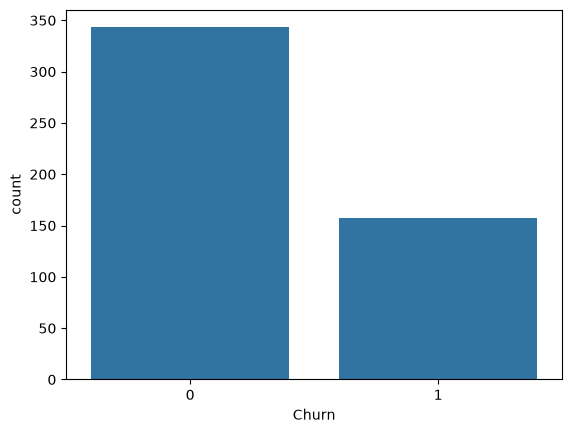

In [6]:
sns.countplot(data=df,x='Churn')


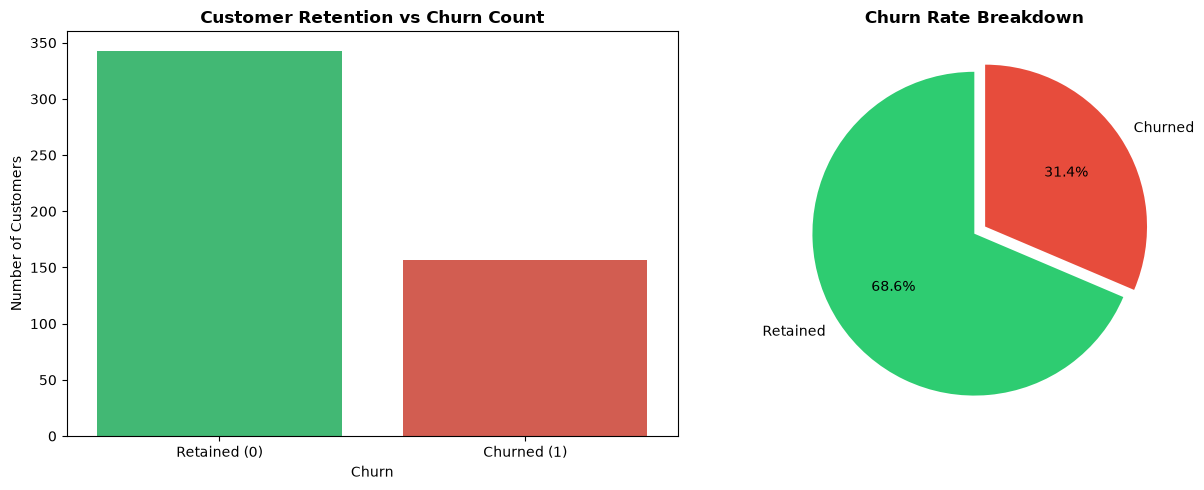

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.countplot(data=df,x='Churn',palette=['#2ecc71','#e74c3c'],ax=axes[0])
axes[0].set_title('Customer Retention vs Churn Count',fontsize=12,fontweight='bold')
axes[0].set_xticklabels(['Retained (0)','Churned (1)'])
axes[0].set_ylabel('Number of Customers')

churn_counts=df['Churn'].value_counts()
axes[1].pie(churn_counts,labels=['Retained','Churned'],autopct='%1.1f%%',
            colors=['#2ecc71','#e74c3c'],startangle=90,explode=(0,0.08))
axes[1].set_title('Churn Rate Breakdown',fontsize=12,fontweight='bold')
plt.tight_layout()
plt.show()

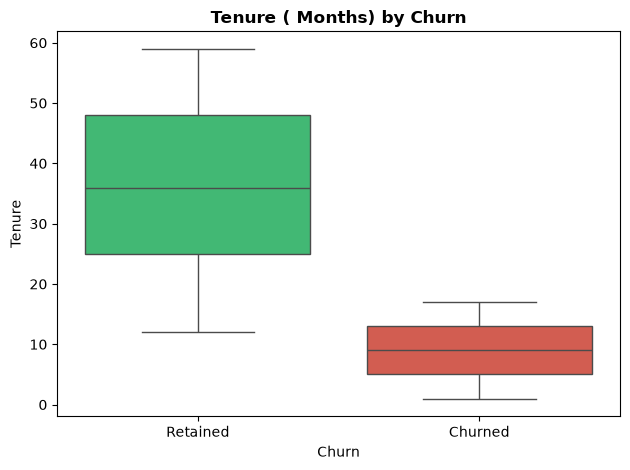

In [8]:
#Numerical Feature Distributions by Churn Status
# Tenure vs Churn

sns.boxplot(data=df,x='Churn',y='Tenure',palette=['#2ecc71','#e74c3c'])
plt.title('Tenure ( Months) by Churn',fontweight='bold')
plt.xticks([0,1],['Retained','Churned'])
plt.tight_layout()
plt.show()

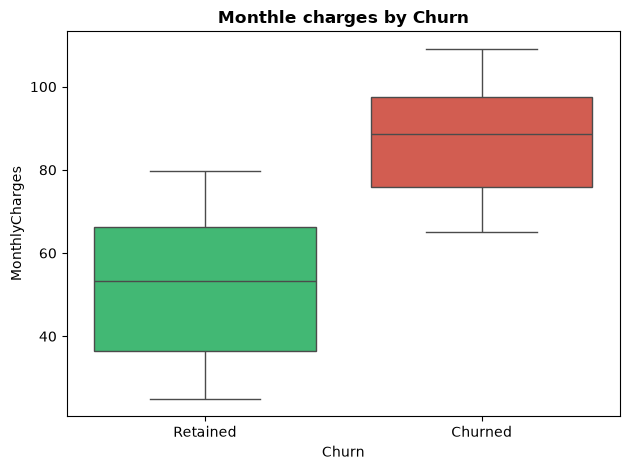

In [9]:
sns.boxplot(data=df,x='Churn',y='MonthlyCharges',palette=['#2ecc71','#e74c3c'])
plt.title('Monthle charges by Churn',fontweight='bold')
plt.xticks([0,1],['Retained','Churned'])
plt.tight_layout()
plt.show()

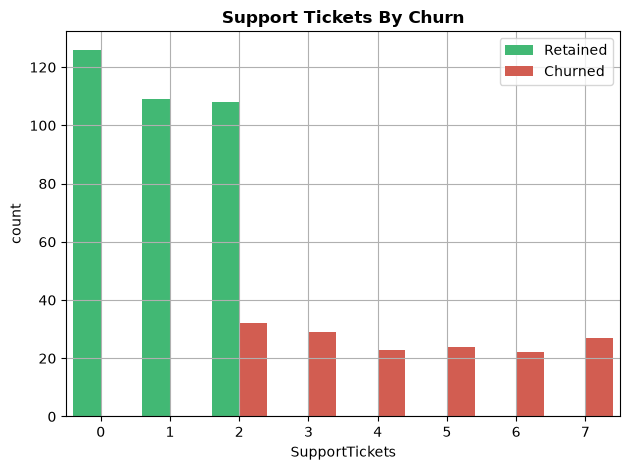

In [10]:
sns.countplot(data=df,x='SupportTickets',hue='Churn',palette=['#2ecc71','#e74c3c'])
plt.title("Support Tickets By Churn",fontweight='bold')
plt.legend(['Retained','Churned'])
plt.grid()
plt.tight_layout()
plt.show()

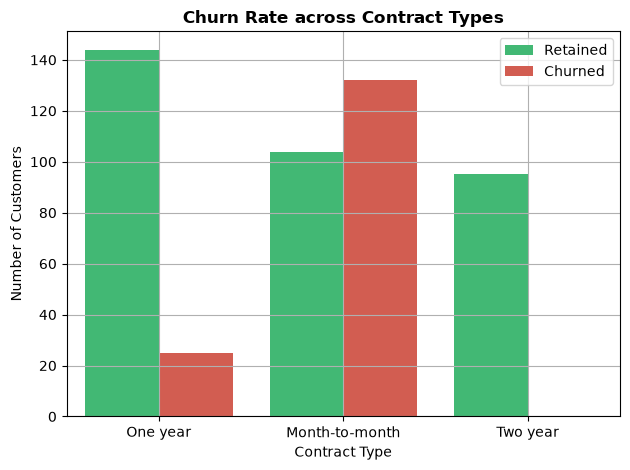

In [11]:
sns.countplot(data=df,x='Contract',hue='Churn',palette=['#2ecc71','#e74c3c'])
plt.title("Churn Rate across Contract Types",fontweight='bold')
plt.xlabel("Contract Type")
plt.ylabel('Number of Customers')
plt.legend(['Retained','Churned'])
plt.grid()
plt.tight_layout()
plt.show()

In [12]:
#NLP Behavior Analysis
#(Text Mining Customer Reviews)

# Sample Customer Feedback 
print("--- Sample Feedback from Retained Customers ---")
for text in df[df['Churn']==0]['CustomerFeedback'].head(5):
    print(f" [Retained]: {text}")

print("--- Sample Feedback from Churned Customers ---")
for text in df[df['Churn']==1]['CustomerFeedback'].head(5):
    print(f" [Churned]: {text}")

--- Sample Feedback from Retained Customers ---
 [Retained]: Customer support was very helpful and polite.
 [Retained]: Smooth connection and fair monthly prices.
 [Retained]: Excellent coverage and fast streaming experience.
 [Retained]: Great service, very happy with internet speed!
 [Retained]: Easy billing process and fast resolution.
--- Sample Feedback from Churned Customers ---
 [Churned]: Bad experience, moving to another provider soon.
 [Churned]: Cancel my subscription, worst customer care ever.
 [Churned]: Monthly charges are way too expensive for bad service.
 [Churned]: Cancel my subscription, worst customer care ever.
 [Churned]: Frequent network outages, very disappointed.


In [13]:
# Data Preprocessing and nlp 
#one hot encoding
df_contract_encoded=pd.get_dummies(df[['Contract']],drop_first=True,dtype=int)


#tfidf assigns weights to words give imp to words and changes words to numeric
tfidf_vectorizer=TfidfVectorizer(max_features=15,stop_words='english',ngram_range=(1,2))
text_features=tfidf_vectorizer.fit_transform(df['CustomerFeedback']).toarray()

text_feature_names=[f'text{word}' for word in tfidf_vectorizer.get_feature_names_out()]
df_text_encoded=pd.DataFrame(text_features,columns=text_feature_names)
print(df_text_encoded)

df_numeric=df[['Tenure','MonthlyCharges','SupportTickets']]

x=pd.concat([df_numeric,df_contract_encoded,df_text_encoded],axis=1)
y=df['Churn']


print(f"Combined Feature Matrix X shape: {x.shape[0]} samples, {x.shape[1]} features")
print("\nfeature Column List:")
print(list(x.columns))

     textcare  textconnection  textcustomer  textcustomer care  textexcellent  \
0         0.0        0.000000           1.0                0.0       0.000000   
1         0.0        0.710409           0.0                0.0       0.000000   
2         0.0        0.000000           0.0                0.0       0.473972   
3         0.0        0.000000           0.0                0.0       0.000000   
4         0.0        0.000000           0.0                0.0       0.000000   
..        ...             ...           ...                ...            ...   
495       0.0        0.000000           0.0                0.0       0.000000   
496       0.0        0.000000           0.0                0.0       0.473972   
497       0.0        0.000000           0.0                0.0       0.000000   
498       0.0        1.000000           0.0                0.0       0.000000   
499       0.0        0.000000           0.0                0.0       0.000000   

     textexcellent coverage

In [14]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42,stratify=y)
print(f"Training set size: {x_train.shape[0]} samples")
print(f"Testing set size: {x_test.shape[0]} samples")

model_lr=LogisticRegression(max_iter=1000,random_state=42)
model_lr.fit(x_train,y_train)
y_pred_lr=model_lr.predict(x_test)
acc_lr=accuracy_score(y_test,y_pred_lr)

model_rf=RandomForestClassifier(n_estimators=100,random_state=42)
model_rf.fit(x_train,y_train)
y_pred_rf=model_rf.predict(x_test)
acc_rf=accuracy_score(y_test,y_pred_rf)

print(f"Accuracy using LogisticRegression: {acc_lr*100:.2f} %")
print(f"Accuracy using RandomForest: {acc_rf*100:.2f} %")

Training set size: 400 samples
Testing set size: 100 samples
Accuracy using LogisticRegression: 100.00 %
Accuracy using RandomForest: 100.00 %


23-7-26

Day-22(24)

Thursday

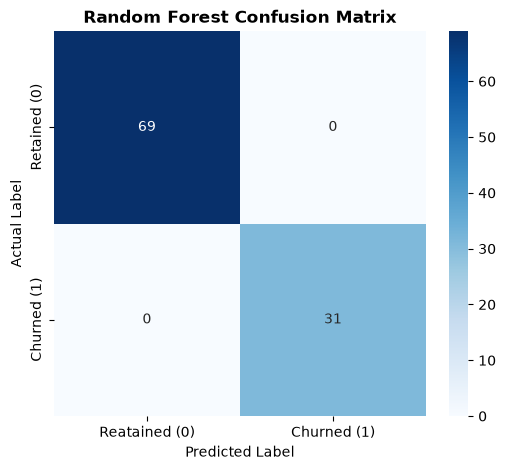

In [15]:
cm=confusion_matrix(y_test,y_pred_rf)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
            xticklabels=['Reatained (0)','Churned (1)'],
            yticklabels=['Retained (0)','Churned (1)'])
plt.title('Random Forest Confusion Matrix',fontsize=12,fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [16]:
# Classification Report
print("--- Detailed Classification Report (Random Forest) ---")
print(classification_report(y_test,y_pred_rf,target_names=['Retained (0)','Churned (1)']))

--- Detailed Classification Report (Random Forest) ---
              precision    recall  f1-score   support

Retained (0)       1.00      1.00      1.00        69
 Churned (1)       1.00      1.00      1.00        31

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



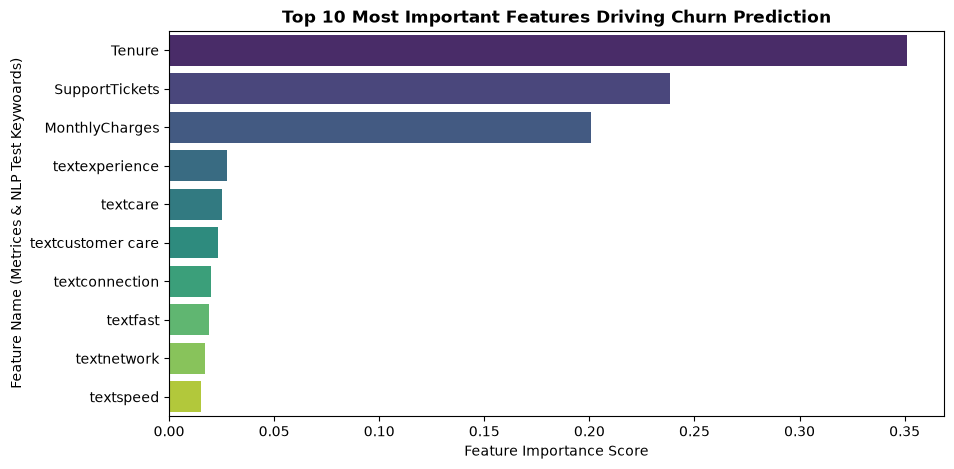

In [17]:
feature_importances=pd.Series(model_rf.feature_importances_,index=x.columns)
top_features=feature_importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_features.values,y=top_features.index,palette='viridis')
plt.title('Top 10 Most Important Features Driving Churn Prediction',fontsize=12,fontweight='bold')
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature Name (Metrices & NLP Test Keywoards)')
plt.show()

In [24]:
def predict_customer_churn(tenure,monthly_charges,support_tickets,contract_type,feedback_text):
    input_dict={
        'Tenure':[tenure],
        'MonthlyCharges':[monthly_charges],
        'SupportTickets':[support_tickets],
        'Contract_One year':[1 if contract_type == 'One year' else 0],
        'Contract_Two year':[1 if contract_type == 'Two year' else 0],
    }

    text_vectorized=tfidf_vectorizer.transform([feedback_text]).toarray()
    for i,col_name in enumerate(text_feature_names):
        input_dict[col_name]=[text_vectorized[0][i]]

    df_input=pd.DataFrame(input_dict)[x.columns]

    churn_prob=model_rf.predict_proba(df_input)[0][1]
    is_churn=churn_prob >=0.5

    print("="*60)
    print("         CUSTOMER CHURN RISK ASSESSMENT REPORT         ")
    print("=" * 60)
    print(f"Customer Input Profile:")
    print(f"    • Tenure            : {tenure} months")
    print(f"    • Monthly Bill      : ${monthly_charges:.2f}")
    print(f"    • Support Tickets   : {support_tickets}")
    print(f"    • Contract Type     : {contract_type}")
    print(f"    • Feedback Review   : {feedback_text}")
    print("-" * 60)
    print(f" CHURN PROBABILITY    : {churn_prob * 100:.1f}%")

    if is_churn:
        print(" RISK STATUS         : ⚠️ HIGH RISK OF CHURNING (DANGER)")
        print(" SUGGESTED ACTION    : Trigger Retention Offer!")
        print("                     -> offer 15% discount on 1-year Contreact")
        print("                     -> Schedule priority customer support callback.")
    else:
        print(" RISK STATUS          : RETAINED (LOW RISK)")
        print(" SUGGESTED ACTION     : No intervention needed.Send thank you offer.")
    print("="*60)

#Test Cases
predict_customer_churn(
    tenure=2,
    monthly_charges=95.50,
    support_tickets=5,
    contract_type='Month-to-month',
    feedback_text="Terrible internet speed,disconnects constantly! Overpriced charges."
)
print("\n")

predict_customer_churn(
    tenure=36,
    monthly_charges=45.00,
    support_tickets=0,
    contract_type='Two year',
    feedback_text="Love the Service,smooth connection and very helpful customer care!"
)



         CUSTOMER CHURN RISK ASSESSMENT REPORT         
Customer Input Profile:
    • Tenure            : 2 months
    • Monthly Bill      : $95.50
    • Support Tickets   : 5
    • Contract Type     : Month-to-month
    • Feedback Review   : Terrible internet speed,disconnects constantly! Overpriced charges.
------------------------------------------------------------
 CHURN PROBABILITY    : 100.0%
 RISK STATUS         : ⚠️ HIGH RISK OF CHURNING (DANGER)
 SUGGESTED ACTION    : Trigger Retention Offer!
                     -> offer 15% discount on 1-year Contreact
                     -> Schedule priority customer support callback.


         CUSTOMER CHURN RISK ASSESSMENT REPORT         
Customer Input Profile:
    • Tenure            : 36 months
    • Monthly Bill      : $45.00
    • Support Tickets   : 0
    • Contract Type     : Two year
    • Feedback Review   : Love the Service,smooth connection and very helpful customer care!
-----------------------------------------------------

In [19]:
import joblib
import os

os.makedirs("models", exist_ok=True)

In [20]:
joblib.dump(model_rf, "models/customer_churn_model.pkl")

['models/customer_churn_model.pkl']

In [21]:
joblib.dump(tfidf_vectorizer,
            "models/tfidf_vectorizer.pkl")

['models/tfidf_vectorizer.pkl']

In [22]:
joblib.dump(
    list(x.columns),
    "models/feature_names.pkl"
)

['models/feature_names.pkl']

In [23]:
joblib.dump(
    text_feature_names,
    "models/text_feature_names.pkl"
)

['models/text_feature_names.pkl']